#### Overlapping Mitigation

Using TomeKLinks

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../laptopprice_dataset_cleaned.csv")
df

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,0,1,0,0,0,1,0,1,0,0
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,0,1,0,0,0,1,0,1,0,0
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,0,1,0,0,0,1,0,0,1,0
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,0,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,4,2.20,10.555257,0,0,100.454670,500,0,0,0,...,0,0,1,0,0,0,1,0,0,1
1269,4,1.80,10.433899,1,1,157.350512,0,128,0,0,...,0,0,1,0,0,1,0,0,0,1
1270,16,1.30,11.288115,1,1,276.053530,0,512,0,0,...,0,0,1,0,0,1,0,0,0,1
1271,2,1.50,9.409283,0,0,111.935204,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1


<Axes: xlabel='target_binned', ylabel='Count'>

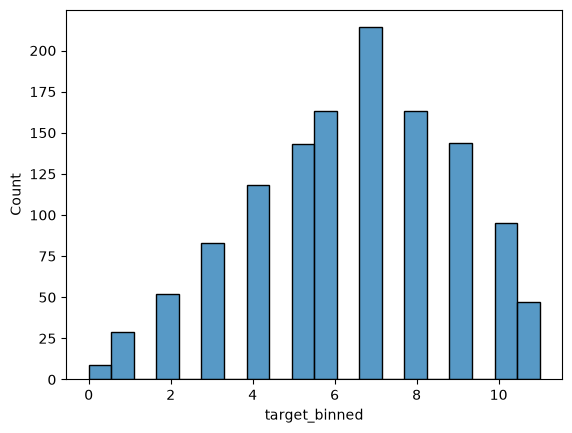

In [10]:
# let's filter some extreme outliers on the high end
df.query("Price <= Price.quantile(0.99)", inplace=True)

# Create 12 bins of price. 
target = "Price"
df['target_binned'] = pd.cut(df[target], bins=12, labels=False)

# That looks like so.
sns.histplot(df, x="target_binned")

In [11]:
df.head()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,1,0,0,0,1,0,1,0,0,8
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,1,0,0,0,1,0,1,0,0,6
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,1,0,0,0,1,0,0,1,0,4
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,1,0,1,0,0,1,0,0,11
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,1,0,0,0,1,0,1,0,0,9


<Axes: xlabel='Weight', ylabel='Ppi'>

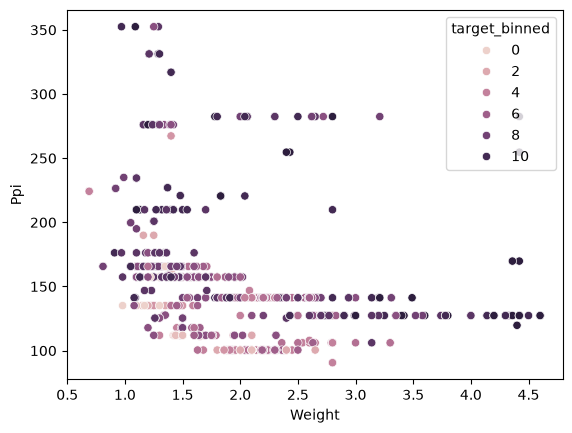

In [12]:
# Now let's take a particularly nasty overlap. Here.
sns.scatterplot(df, x="Weight", y="Ppi", hue="target_binned")

# In real life, does this overlap seem feasible? Probably.
# There's always some overlap (laptops with different specs can cost the same).

# But say this didn't reflect reality and there's some reason to 
# fix the overlap (to which there are many)...


#### TomeKLinks

In [13]:
from imblearn.under_sampling import TomekLinks

df = df.dropna()

# X y split to prevent data leakage
X = df.drop(columns="target_binned", axis=1)
y = df["target_binned"]

# Let's use vanilla tomeklinks
tomek = TomekLinks()

# Fit and resample.
X_resampled, y_resampled = tomek.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["target_binned"] = y_resampled
df_resampled

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,1,0,0,0,1,0,1,0,0,8
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,1,0,0,0,1,0,1,0,0,6
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,1,0,0,0,1,0,0,1,0,4
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,1,0,1,0,0,1,0,0,11
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,1,0,0,0,1,0,1,0,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
864,8,2.30,10.667632,0,0,100.454670,1000,0,0,0,...,0,1,0,1,0,0,0,1,0,6
865,2,1.17,9.317895,0,0,135.094211,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
866,4,2.20,10.555257,0,0,100.454670,500,0,0,0,...,0,1,0,0,0,1,0,0,1,5
867,16,1.30,11.288115,1,1,276.053530,0,512,0,0,...,0,1,0,0,1,0,0,0,1,8


Text(0.5, 1.0, 'Original')

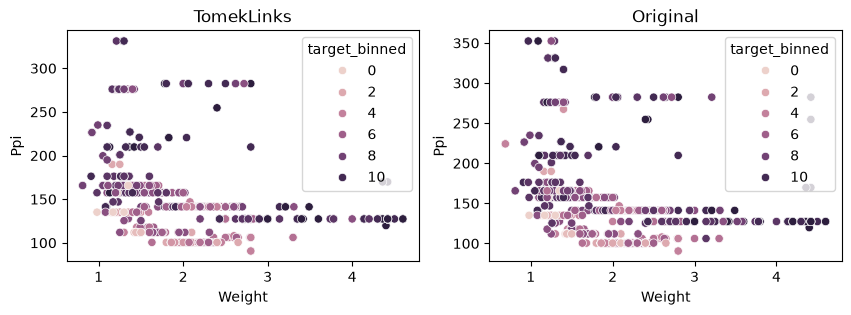

In [ ]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df_resampled, x="Weight", y="Ppi", hue="target_binned", ax=axes[0])
sns.scatterplot(df, x="Weight", y="Ppi", hue="target_binned", ax=axes[1]) 

axes[0].set_title("TomekLinks")
axes[1].set_title("Original")

# Quite underwhelming... The TomekLinks plot looks almost identical to the original.
# Only a few points were removed (e.g. some of the high Ppi points), and the dense area
# around Weight 1-2.5 and Ppi 100-170 still has many different price bins mixed together.
# That sort of makes sense though. Tomek is notoriously conservative, even with
# large amounts of data. Hence why it's commonly used with SMOTE first.

In [15]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

# It only dropped about 60 rows.

(1260, 45)
(869, 45)
